# Model comparison

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as st

sys.path.insert(0, "Project 1")
from part1.analysis import BenavoliCorrelatedT

SYSTEMS = {  # short name -> results folder
    "MLP": Path("Project 1/results/mlp_indicator-lemmas"),
    "Embed & pool": Path("results/final_embed_pool_s1_trial19"),
    "LSTM": Path("results/final_lstm_s1_trial43"),
}
PAIRS = list(combinations(SYSTEMS, 2))
N_SEEDS, K_FOLDS = 3, 5
ROPE_SIZE = 0.01      # as in Project 1: differences under 1 point count as practically equivalent
DECISION_PROB = 0.95

cv = pd.concat([pd.read_csv(d / "cv_scores.csv").assign(model=name) for name, d in SYSTEMS.items()],
               ignore_index=True)[["model", "seed", "fold", "accuracy", "f1"]]
RUNS = [(s, f) for s in range(N_SEEDS) for f in range(K_FOLDS)]
for name, g in cv.groupby("model"):
    assert sorted(zip(g.seed, g.fold)) == RUNS, f"missing or repeated runs for {name}"

## Scores

In [2]:
cv.groupby("model", sort=False)[["accuracy", "f1"]].agg(["mean", "std"]).round(4)

accuracy              f1        
                 mean     std    mean     std
model                                        
MLP            0.7032  0.0021  0.6678  0.0037
Embed & pool   0.7006  0.0021  0.6673  0.0026
LSTM           0.7274  0.0025  0.7068  0.0036

## Bayesian correlated t-test

In [3]:
def compare(a, b, metric="f1"):
    scores = cv.set_index(["model", "seed", "fold"])[metric]
    # the same (seed, fold) order for every system, so the scores are paired
    return BenavoliCorrelatedT(*(scores.loc[m].loc[RUNS].to_numpy() for m in (a, b)), runs=N_SEEDS, names=[a, b])

In [4]:
def pair_table(metric, rope=ROPE_SIZE):
    rows = []
    for a, b in PAIRS:
        p = compare(a, b, metric)
        p_a, p_tie, p_b = p.probs(rope)
        lo, hi = st.t.interval(0.95, p.df, p.mean_diff, p.std)
        rows.append({"A": a, "B": b, "mean diff (B-A)": p.mean_diff, "95% low": lo, "95% high": hi,
                     "P(A better)": p_a, "P(tie)": p_tie, "P(B better)": p_b})
    return pd.DataFrame(rows)


for metric in ("f1", "accuracy"):
    print(metric)
    display(pair_table(metric).round(4))

f1


,A,B,mean diff (B-A),95% low,95% high,P(A better),P(tie),P(B better)
0,MLP,Embed & pool,-0.0005,-0.0056,0.0046,0.0006,0.9991,0.0003
1,MLP,LSTM,0.0390,0.0343,0.0437,0.0000,0.0000,1.0000
2,Embed & pool,LSTM,0.0395,0.0348,0.0441,0.0000,0.0000,1.0000


accuracy


,A,B,mean diff (B-A),95% low,95% high,P(A better),P(tie),P(B better)
0,MLP,Embed & pool,-0.0026,-0.0052,0.0000,0.0,1.0,0.0
1,MLP,LSTM,0.0243,0.0205,0.0281,0.0,0.0,1.0
2,Embed & pool,LSTM,0.0269,0.0233,0.0304,0.0,0.0,1.0


## Forest plot

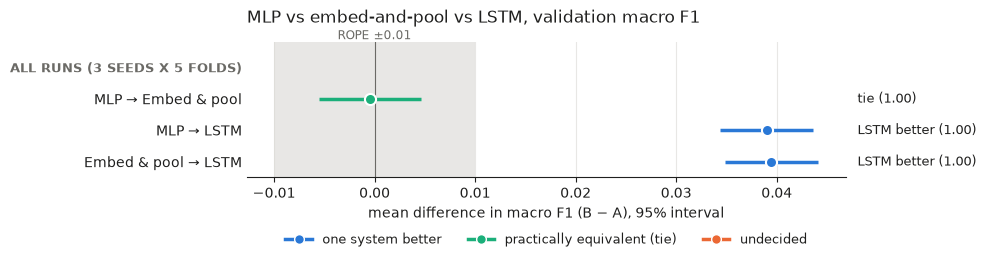

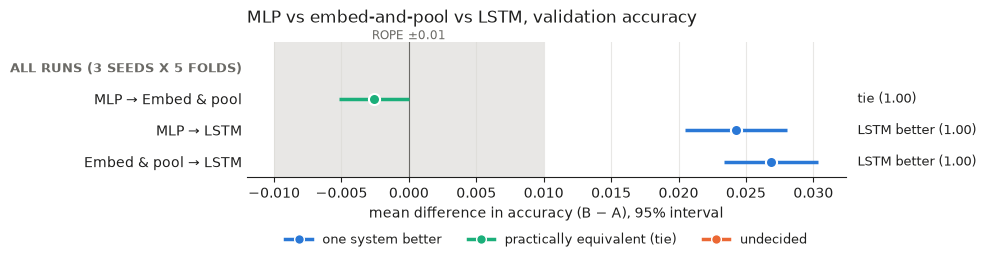

In [5]:
from matplotlib.lines import Line2D

# mark colour by result (categorical slots 1-3); the text stays in ink so it is readable on any colour
RESULT_COLOURS = {"better": "#2a78d6", "tie": "#1baf7a", "undecided": "#eb6834"}

# dark text and axes on the white background, whatever matplotlib theme the notebook runs with
LIGHT_STYLE = {"text.color": "#1f1f1e", "axes.labelcolor": "#1f1f1e", "axes.titlecolor": "#1f1f1e",
               "xtick.color": "#1f1f1e", "ytick.color": "#1f1f1e", "xtick.labelcolor": "#1f1f1e",
               "ytick.labelcolor": "#1f1f1e", "axes.edgecolor": "#1f1f1e", "legend.labelcolor": "#1f1f1e",
               "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}

def plot_forest(*args, **kwargs):
    """See _plot_forest; draws it with the light style."""
    with plt.rc_context(LIGHT_STYLE):
        _plot_forest(*args, **kwargs)

def _plot_forest(groups, title, metric="f1", rope_size=ROPE_SIZE, decision_prob=DECISION_PROB, interval=0.95, save_as=None):
    """groups: {group heading: [(row label, sys_a, sys_b), ...]}. One row per comparison, grouped under headings.
    save_as: optional file name in figures/ (white background, for slides)."""
    rows = []  # (y label, posterior or None for a heading)
    for heading, pairs in groups.items():
        present = [(label, compare(a, b, metric)) for label, a, b in pairs ]
        if present:
            rows.append((heading, None))
            rows.extend(present)

    ink, muted = "#1f1f1e", "#6b6a66"
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(rows) + 1.6), facecolor="white")
    ax.set_facecolor("white")
    ax.axvspan(-rope_size, rope_size, color="#b4b2ab", alpha=0.3, lw=0)
    ax.axvline(0, color=muted, lw=0.8)
    for y, (label, p) in enumerate(rows):
        if p is None:
            continue
        p_a, p_tie, p_b = p.probs(rope_size)
        name_a, name_b = label.split(" → ")  # name the winner instead of "A" / "B"
        regions = {f"{name_a} better": p_a, "tie": p_tie, f"{name_b} better": p_b}
        best = max(regions, key=regions.get)
        result = "undecided" if regions[best] < decision_prob else ("tie" if best == "tie" else "better")
        lo, hi = st.t.interval(interval, p.df, p.mean_diff, p.std)
        ax.hlines(y, lo, hi, color=RESULT_COLOURS[result], lw=2.5)
        ax.plot(p.mean_diff, y, "o", color=RESULT_COLOURS[result], ms=8, mec="white", mew=1.5)
        decision = f"{best} ({regions[best]:.2f})" if regions[best] >= decision_prob else f"undecided ({best} {regions[best]:.2f})"
        ax.text(1.02, y, decision, transform=ax.get_yaxis_transform(), va="center", fontsize=9.5,
                color=ink if regions[best] >= decision_prob else muted)

    ax.set_yticks(range(len(rows)), [label if p is not None else label.upper() for label, p in rows])
    for tick, (_, p) in zip(ax.get_yticklabels(), rows):
        if p is None:
            tick.set_fontweight("bold"); tick.set_fontsize(9); tick.set_color(muted)
    ax.set_ylim(len(rows) - 0.5, -0.8)  # first row at the top
    ax.text(0, -0.8, f"ROPE ±{rope_size}", ha="center", va="bottom", fontsize=8.5, color=muted)
    ax.set_xlabel(f"mean difference in {'macro F1' if metric == 'f1' else metric} (B − A), {interval:.0%} interval")
    ax.tick_params(axis="y", length=0)
    ax.spines[["left", "top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#d9d8d4", alpha=0.6)
    ax.set_title(title, loc="left", fontsize=12, pad=14)
    handles = [Line2D([], [], color=colour, lw=2.5, marker="o", ms=7, mec="white", label=name)
               for name, colour in [("one system better", RESULT_COLOURS["better"]),
                                    ("practically equivalent (tie)", RESULT_COLOURS["tie"]),
                                    ("undecided", RESULT_COLOURS["undecided"])]]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, frameon=False, fontsize=9.5)
    fig.tight_layout()
    if save_as:
        fig.savefig(Path("./figures") / save_as, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
GROUPS = {"All runs (3 seeds x 5 folds)": [(f"{a} → {b}", a, b) for a, b in PAIRS]}
plot_forest(GROUPS, "MLP vs embed-and-pool vs LSTM, validation macro F1", "f1", save_as="rope_forest_project2_f1.png")
plot_forest(GROUPS, "MLP vs embed-and-pool vs LSTM, validation accuracy", "accuracy",
            save_as="rope_forest_project2_accuracy.png")

In [6]:
# robustness: how the decisions change with the ROPE width
for metric in ("f1", "accuracy"):
    for rope in (0.0025, 0.005, 0.01, 0.02):
        print(f"{metric}, ROPE ±{rope}")
        display(pair_table(metric, rope).round(4))

f1, ROPE ±0.0025


,A,B,mean diff (B-A),95% low,95% high,P(A better),P(tie),P(B better)
0,MLP,Embed & pool,-0.0005,-0.0056,0.0046,0.2044,0.6825,0.1131
1,MLP,LSTM,0.0390,0.0343,0.0437,0.0000,0.0000,1.0000
2,Embed & pool,LSTM,0.0395,0.0348,0.0441,0.0000,0.0000,1.0000


f1, ROPE ±0.005


,A,B,mean diff (B-A),95% low,95% high,P(A better),P(tie),P(B better)
0,MLP,Embed & pool,-0.0005,-0.0056,0.0046,0.0384,0.9438,0.0178
1,MLP,LSTM,0.0390,0.0343,0.0437,0.0000,0.0000,1.0000
2,Embed & pool,LSTM,0.0395,0.0348,0.0441,0.0000,0.0000,1.0000


f1, ROPE ±0.01


,A,B,mean diff (B-A),95% low,95% high,P(A better),P(tie),P(B better)
0,MLP,Embed & pool,-0.0005,-0.0056,0.0046,0.0006,0.9991,0.0003
1,MLP,LSTM,0.0390,0.0343,0.0437,0.0000,0.0000,1.0000
2,Embed & pool,LSTM,0.0395,0.0348,0.0441,0.0000,0.0000,1.0000


... (6 outputs left out)

accuracy, ROPE ±0.01


,A,B,mean diff (B-A),95% low,95% high,P(A better),P(tie),P(B better)
0,MLP,Embed & pool,-0.0026,-0.0052,0.0000,0.0,1.0,0.0
1,MLP,LSTM,0.0243,0.0205,0.0281,0.0,0.0,1.0
2,Embed & pool,LSTM,0.0269,0.0233,0.0304,0.0,0.0,1.0


accuracy, ROPE ±0.02


,A,B,mean diff (B-A),95% low,95% high,P(A better),P(tie),P(B better)
0,MLP,Embed & pool,-0.0026,-0.0052,0.0000,0.0,1.0000,0.0000
1,MLP,LSTM,0.0243,0.0205,0.0281,0.0,0.0151,0.9849
2,Embed & pool,LSTM,0.0269,0.0233,0.0304,0.0,0.0005,0.9995


## Summary